In [1]:
# tokenizer

import os
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Whitespace


class BPETokenizer:
    def __init__(self, vocab_size=30000, save_path="bpe_tokenizer.json"): #Final vocabulary will have 30,000 tokens
        self.vocab_size_value = vocab_size
        self.save_path = save_path
        self.tokenizer = None

    def train(self, corpus_iterator):
        if os.path.exists(self.save_path):
            print("Loading existing tokenizer")
            self.load()
            return

        print("Training BPE tokenizer")
        self.tokenizer = Tokenizer(BPE(unk_token="<unk>"))
        self.tokenizer.pre_tokenizer = Whitespace() #First split text by spaces

        trainer = BpeTrainer(
            vocab_size=self.vocab_size_value,
            min_frequency=1,
            special_tokens=["<pad>", "<unk>"]
        )


        self.tokenizer.train_from_iterator(corpus_iterator, trainer=trainer)
        self.tokenizer.save(self.save_path)
        print("tokenizer saved")

    def load(self):
        self.tokenizer = Tokenizer.from_file(self.save_path)

    def encode(self, text):
        return self.tokenizer.encode(text).ids

    def decode(self, ids):
        return self.tokenizer.decode(ids)

    def get_vocab_size(self):
        return self.tokenizer.get_vocab_size()


In [8]:
# cbow 

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import random
import torch.nn.functional as F
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class CBOWDataset(Dataset):
    def __init__(self, tokenized_corpus, window_size=5):
        self.data = []
        self.window_size = window_size

        for sentence in tokenized_corpus:
            if len(sentence) < 2 * window_size + 1:
                continue
            for i in range(window_size, len(sentence) - window_size):
                context = (
                    sentence[i - window_size:i] +
                    sentence[i + 1:i + window_size + 1]
                )
                target = sentence[i]
                self.data.append((context, target))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        context, target = self.data[idx]
        return torch.tensor(context), torch.tensor(target)
 
class CBOWBinary(nn.Module):
    def __init__(self, vocab_size, embedding_dim=384):
        super().__init__()
        self.input_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.output_embedding = nn.Embedding(vocab_size, embedding_dim)

    def forward(self, context, target):
        # Context → input embedding
        context_embed = self.input_embedding(context)
        context_vector = context_embed.mean(dim=1)

        # Target → output embedding
        target_embed = self.output_embedding(target)

        dot = torch.sum(context_vector * target_embed, dim=1)
        return dot
from collections import Counter

def build_negative_sampling_distribution(tokenized_corpus, vocab_size):
    counter = Counter()

    for sentence in tokenized_corpus:
        counter.update(sentence)

    freq = torch.zeros(vocab_size)

    for word_id, count in counter.items():
        freq[word_id] = count

    freq = freq ** 0.75
    freq = freq / freq.sum()

    return freq




def train_cbow(tokenized_corpus,
               vocab_size,
               embedding_dim=384,
               window_size=5,
               epochs=5,
               batch_size=512,
               lr=0.001,
               save_path="cbow_model.pt"):

    dataset = CBOWDataset(tokenized_corpus, window_size=window_size)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    model = CBOWBinary(vocab_size, embedding_dim).to(device)

    neg_distribution = build_negative_sampling_distribution(
    tokenized_corpus,
    vocab_size
    ).to(device)


    criterion = nn.BCEWithLogitsLoss(reduction="sum")
    optimizer = optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        total_loss = 0
        for context, target in loader:
            context = context.to(device)
            target = target.to(device)
        
            batch_size = target.size(0)
            optimizer.zero_grad()
        
            # POSITIVE samples
            labels_pos = torch.ones(batch_size, device=device)
            logits_pos = model(context, target)
            loss_pos = criterion(logits_pos, labels_pos)
        
            # NEGATIVE samples (match friend: 5 negatives per positive)
            num_negatives = 5

            # Sample negatives using multinomial
            neg_targets = torch.multinomial(
                neg_distribution,
                batch_size * num_negatives,
                replacement=True
            ).view(batch_size, num_negatives)
            
            # Repeat context for each negative
            context_expanded = context.unsqueeze(1).repeat(1, num_negatives, 1)
            context_expanded = context_expanded.view(-1, context.size(1))
            
            neg_targets_flat = neg_targets.view(-1)
            
            # Compute logits for negatives
            logits_neg = model(context_expanded, neg_targets_flat)
            
            labels_neg = torch.zeros(batch_size * num_negatives, device=device)
            
            loss_neg = criterion(logits_neg, labels_neg)
            
            loss = (loss_pos + loss_neg) / batch_size


        
            loss.backward()
            optimizer.step()
        
            total_loss += loss.item()


        avg_loss = total_loss / len(loader)
        print(f"Epoch {epoch+1} | Avg Loss: {avg_loss:.4f}")


    torch.save(model.state_dict(), save_path)
    print("CBOW model saved")

    return model




In [9]:
# sentiment_pipeline

import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

nltk.download("vader_lexicon")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def get_document_embeddings(model, tokenized_texts):
    embeddings = []

    with torch.no_grad():
        for tokens in tokenized_texts:
            if len(tokens) == 0:
                embeddings.append(np.zeros(model.input_embedding.embedding_dim))
                continue

            tensor = torch.tensor(tokens).unsqueeze(0).to(device)
            word_embeds = model.input_embedding(tensor)

            doc_embed = word_embeds.mean(dim=1).cpu().numpy()
            embeddings.append(doc_embed[0])

    return np.array(embeddings)


def run_sentiment_pipeline(tokenizer, cbow_model):

    texts = []
    labels = []

    label_map = {
        "negative": 0,
        "neutral": 1,
        "positive": 2
    }

    file_path = "/kaggle/input/datasets/sharanyabhatia/financial-1/Sentences_50Agree.txt"

    with open(file_path, "r", encoding="latin-1") as f:
        for line in f:
            if "@" not in line:
                continue

            sentence, label = line.strip().rsplit("@", 1)
            label = label.lower().strip()

            if label not in label_map:
                continue

            texts.append(sentence)
            labels.append(label_map[label])

    labels = np.array(labels)

    tokenized = [tokenizer.encode(t) for t in texts]
    doc_vectors = get_document_embeddings(cbow_model, tokenized)

    X_train, X_test, y_train, y_test, text_train, text_test = train_test_split(
        doc_vectors,
        labels,
        texts,
        test_size=0.2
    )

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    clf = LogisticRegression(max_iter=3000)
    clf.fit(X_train, y_train)

    preds = clf.predict(X_test)

    print("\nCBOW + Logistic Regression")
    print("F1 Macro:", f1_score(y_test, preds, average="macro"))
    print(classification_report(y_test, preds))
    cm = confusion_matrix(y_test, preds)
    
    plt.figure()
    plt.imshow(cm)
    plt.title("CBOW + Logistic Regression Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.colorbar()
    
    plt.xticks(np.arange(3), ["Negative", "Neutral", "Positive"])
    plt.yticks(np.arange(3), ["Negative", "Neutral", "Positive"])
    
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    
    plt.show()


    sia = SentimentIntensityAnalyzer()
    vader_preds = []

    for text in text_test:
        score = sia.polarity_scores(text)["compound"]
        if score >= 0.05:
            vader_preds.append(2)
        elif score <= -0.05:
            vader_preds.append(0)
        else:
            vader_preds.append(1)

    print("\nVADER Baseline")
    print("F1 Macro:", f1_score(y_test, vader_preds, average="macro"))
    print(classification_report(y_test, vader_preds))
    cm_vader = confusion_matrix(y_test, vader_preds)
    
    plt.figure()
    plt.imshow(cm_vader)
    plt.title("VADER Baseline Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.colorbar()
    
    plt.xticks(np.arange(3), ["Negative", "Neutral", "Positive"])
    plt.yticks(np.arange(3), ["Negative", "Neutral", "Positive"])
    
    for i in range(cm_vader.shape[0]):
        for j in range(cm_vader.shape[1]):
            plt.text(j, i, cm_vader[i, j], ha="center", va="center")
    
    plt.show()

    print("\nCases where CBOW is correct but VADER is wrong:\n")

    count = 0
    max_examples = 5
    
    for i in range(len(y_test)):
        if preds[i] == y_test[i] and vader_preds[i] != y_test[i]:
            print("Text:", text_test[i])
            print("True Label:", y_test[i])
            print("CBOW Prediction:", preds[i])
            print("VADER Prediction:", vader_preds[i])
            print("-" * 60)
    
            count += 1
            if count >= max_examples:
                break

    


    return clf


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [10]:
#analogy_utils
import numpy as np
import torch
import torch.nn.functional as F
def analogy_test(word_matrix, words, word_a, word_b, word_c, top_k=5):

    word_to_index = {w: i for i, w in enumerate(words)}

    if word_a not in word_to_index or \
       word_b not in word_to_index or \
       word_c not in word_to_index:
        return "Word not found"

    vec_a = word_matrix[word_to_index[word_a]]
    vec_b = word_matrix[word_to_index[word_b]]
    vec_c = word_matrix[word_to_index[word_c]]

    query = vec_a - vec_b + vec_c
    query = F.normalize(query.unsqueeze(0), p=2, dim=1)

    similarities = torch.matmul(word_matrix, query.squeeze())

    similarities[word_to_index[word_a]] = -1
    similarities[word_to_index[word_b]] = -1
    similarities[word_to_index[word_c]] = -1

    top = torch.topk(similarities, top_k)

    results = []
    for idx, score in zip(top.indices.tolist(), top.values.tolist()):
        results.append((words[idx], float(score)))

    return results


def build_word_embedding_table(model, tokenizer, word_list):

    model.eval()

    with torch.no_grad():
        subword_emb = model.input_embedding.weight #Each row = embedding for one token ID
        subword_emb = F.normalize(subword_emb, p=2, dim=1) 

    word_embeddings = {}
    word_vectors = []

    for word in word_list:
        ids = tokenizer.encode(word)
        if not ids:
            continue

        vec = subword_emb[ids].mean(dim=0) #word vector = average of its subword vectors
        vec = F.normalize(vec.unsqueeze(0), p=2, dim=1).squeeze()
        word_embeddings[word] = vec
        word_vectors.append(vec)

    word_matrix = torch.stack(list(word_embeddings.values()))
    word_list_filtered = list(word_embeddings.keys())

    return word_matrix, word_list_filtered



[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Loading Wikipedia from Kaggle dataset
Total sentences collected: 50000
Loading existing tokenizer
Epoch 1 | Avg Loss: 12.6364
Epoch 2 | Avg Loss: 8.4144
Epoch 3 | Avg Loss: 6.3108
Epoch 4 | Avg Loss: 5.2035
Epoch 5 | Avg Loss: 4.4519
CBOW model saved

CBOW + Logistic Regression
F1 Macro: 0.5726326847894672
              precision    recall  f1-score   support

           0       0.46      0.38      0.42       131
           1       0.74      0.81      0.77       559
           2       0.57      0.49      0.53       280

    accuracy                           0.66       970
   macro avg       0.59      0.56      0.57       970
weighted avg       0.65      0.66      0.65       970



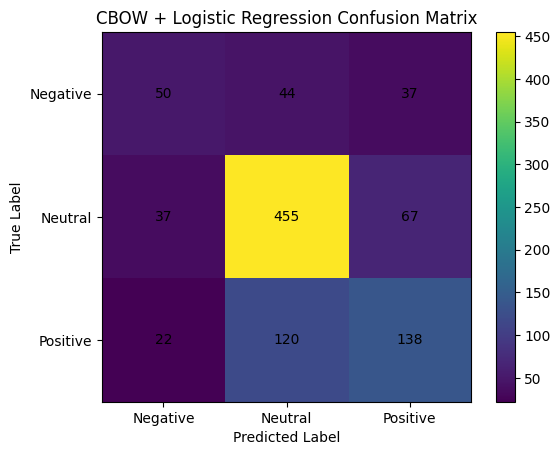


VADER Baseline
F1 Macro: 0.494797703911715
              precision    recall  f1-score   support

           0       0.42      0.32      0.36       131
           1       0.73      0.53      0.61       559
           2       0.41      0.68      0.51       280

    accuracy                           0.54       970
   macro avg       0.52      0.51      0.49       970
weighted avg       0.59      0.54      0.55       970



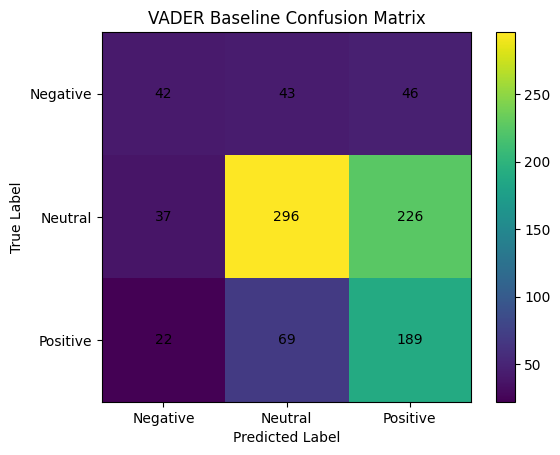


Cases where CBOW is correct but VADER is wrong:

Text: The shopping center will have a prime location right next to the Myllypuro metro station .
True Label: 2
CBOW Prediction: 2
VADER Prediction: 1
------------------------------------------------------------
Text: The business had gross written premiums of EUR152 .4 m (  91.5 m ) in 2000 , a net combined ratio of 133 % and 175 staff in total with offices in the UK , Germany and Benelux .
True Label: 1
CBOW Prediction: 1
VADER Prediction: 0
------------------------------------------------------------
Text: It is also in the process of taking a seat on CapMan 's board - a course which has the support of CapMan management .
True Label: 1
CBOW Prediction: 1
VADER Prediction: 2
------------------------------------------------------------
Text: Result before taxes decreased to nearly EUR 14.5 mn , compared to nearly EUR 20mn in the previous accounting period .
True Label: 0
CBOW Prediction: 0
VADER Prediction: 1
---------------------------

In [11]:
# main

import os
import nltk
nltk.download("punkt")
from nltk.tokenize import sent_tokenize


print("Loading Wikipedia from Kaggle dataset")

wiki_path = "/kaggle/input/datasets/ffatty/plain-text-wikipedia-simpleenglish/AllCombined.txt"

sentences = []



with open(wiki_path, "r", encoding="utf-8") as f:
    for line in f:
        article_sentences = sent_tokenize(line.strip())
        sentences.extend(article_sentences)

        if len(sentences) >= 50000:
            sentences = sentences[:50000]
            break

print("Total sentences collected:", len(sentences))

# Build word list from Wikipedia
word_set = set()
for s in sentences:
    for w in s.lower().split():
        word_set.add(w)

word_list = list(word_set)


tokenizer = BPETokenizer()
tokenizer.train(sentences)

tokenized_wiki = [tokenizer.encode(s) for s in sentences]

model = train_cbow(
    tokenized_wiki,
    vocab_size=tokenizer.get_vocab_size(),
    window_size=5
)

run_sentiment_pipeline(tokenizer, model)


import re

# Build clean word list
word_set = set()

for s in sentences:
    clean_words = re.findall(r"[a-zA-Z]+", s.lower())
    for w in clean_words:
        word_set.add(w)

word_list = list(word_set)

# Build word embedding table once
word_matrix, words = build_word_embedding_table(
    model,
    tokenizer,
    word_list
)

print("\nSemantic Analogy:")
print("\nking - man + woman ≈")

results = analogy_test(
    word_matrix,
    words,
    "king",
    "man",
    "woman"
)

if isinstance(results, str):
    print(results)
else:
    for word, score in results:
        print(f"{word} ({score:.3f})")
